In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Find the project root
current = Path.cwd()

project_root = next(
    (
        p for p in [current, *current.parents]
        if (p / "data" / "processed" / "perishable_inventory.csv").exists()
    ),
    None,
)

if project_root is None:
    raise FileNotFoundError(
        "Dataset not found. Open the notebook inside the WasteWise-AI project."
    )

data_path = project_root / "data" / "processed" / "perishable_inventory.csv"

df = pd.read_csv(data_path)
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("EDA dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Date range:", df["date"].min(), "to", df["date"].max())
print("Number of products:", df["product_id"].nunique())
print("Categories:", df["category"].nunique())

display(df.head())

EDA dataset loaded successfully!
Dataset shape: (1800, 12)
Date range: 2026-04-01 00:00:00 to 2026-09-27 00:00:00
Number of products: 10
Categories: 4


,product_id,date,category,opening_stock,units_received,units_sold,unit_price,discount_pct,days_to_expiry,temperature_c,waste_units,stockout_flag
0,1001,2026-04-01,Dairy,27,0,6,32.0,0,1,4.1,0,0
1,1001,2026-04-02,Dairy,30,12,5,32.0,0,5,3.7,0,0
2,1001,2026-04-03,Dairy,38,0,14,32.0,0,2,4.6,0,0
3,1001,2026-04-04,Dairy,49,0,11,32.0,0,0,5.7,0,0
4,1001,2026-04-05,Dairy,19,13,12,32.0,0,0,3.0,0,0


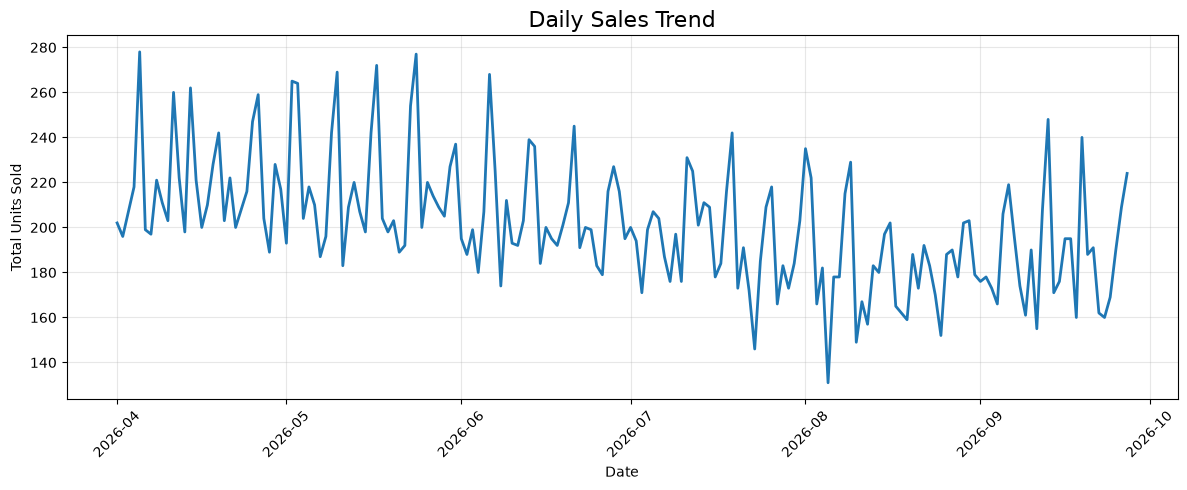

Total daily sales records: 180
Highest daily sales: 278
Lowest daily sales: 131


In [2]:
# Step 2: Daily Sales Trend

daily_sales = (
    df.groupby("date", as_index=False)
    .agg(total_units_sold=("units_sold", "sum"))
    .sort_values("date")
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily_sales["date"],
    daily_sales["total_units_sold"],
    linewidth=2,
)
plt.title("Daily Sales Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Total daily sales records:", len(daily_sales))
print("Highest daily sales:", daily_sales["total_units_sold"].max())
print("Lowest daily sales:", daily_sales["total_units_sold"].min())

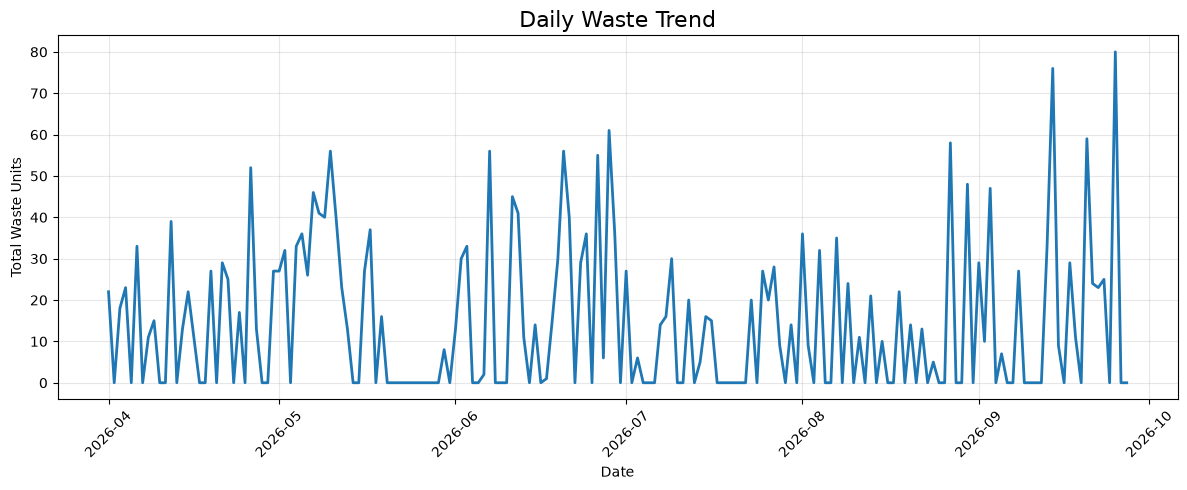

Total recorded waste: 2602
Highest daily waste: 80


In [3]:
# Step 3: Daily Waste Trend

daily_waste = (
    df.groupby("date", as_index=False)
    .agg(total_waste_units=("waste_units", "sum"))
    .sort_values("date")
)

plt.figure(figsize=(12, 5))
plt.plot(
    daily_waste["date"],
    daily_waste["total_waste_units"],
    linewidth=2,
)
plt.title("Daily Waste Trend", fontsize=16)
plt.xlabel("Date")
plt.ylabel("Total Waste Units")
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print("Total recorded waste:", int(daily_waste["total_waste_units"].sum()))
print("Highest daily waste:", daily_waste["total_waste_units"].max())

,category,total_units_sold,total_waste_units
2,Dairy,13239,1056
3,Produce,11428,810
0,Bakery,6585,459
1,Beverage,5015,277


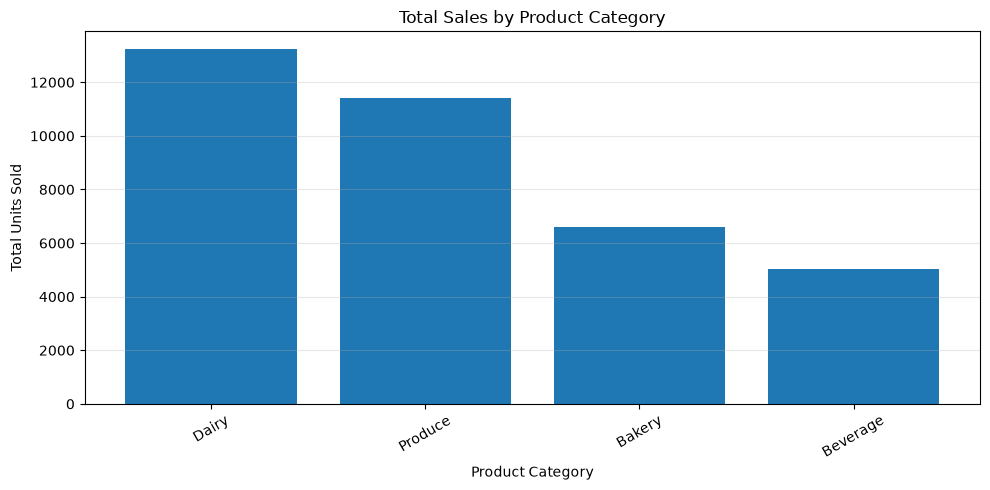

In [4]:
# Step 4: Category-wise Sales Analysis

category_sales = (
    df.groupby("category", as_index=False)
    .agg(
        total_units_sold=("units_sold", "sum"),
        total_waste_units=("waste_units", "sum"),
    )
    .sort_values("total_units_sold", ascending=False)
)

display(category_sales)

plt.figure(figsize=(10, 5))
plt.bar(
    category_sales["category"],
    category_sales["total_units_sold"],
)
plt.title("Total Sales by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Units Sold")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

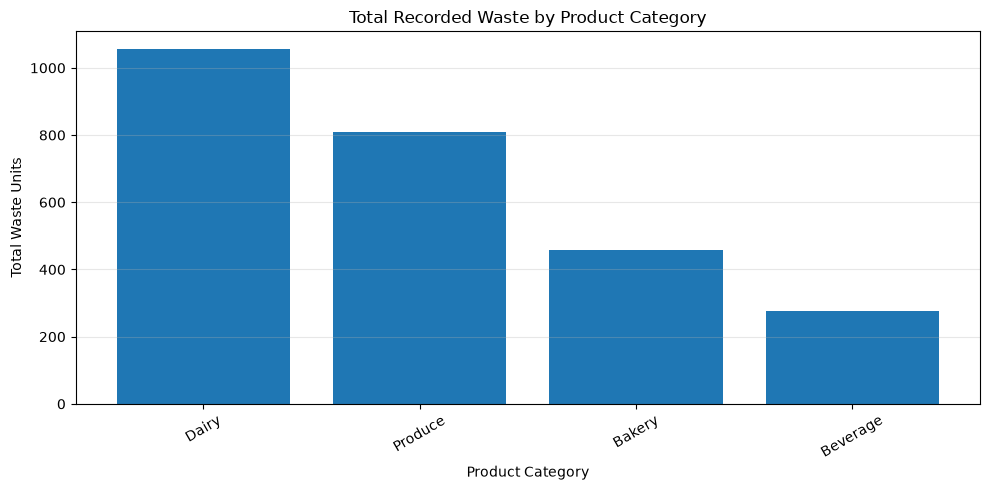

Total recorded waste: 2602
Category with highest recorded waste: Dairy


In [5]:
# Step 5: Category-wise Waste Analysis

plt.figure(figsize=(10, 5))
plt.bar(
    category_sales["category"],
    category_sales["total_waste_units"],
)
plt.title("Total Recorded Waste by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Total Waste Units")
plt.xticks(rotation=30)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

print("Total recorded waste:", int(df["waste_units"].sum()))
print(
    "Category with highest recorded waste:",
    category_sales.loc[
        category_sales["total_waste_units"].idxmax(),
        "category",
    ],
)

STOCKOUT ANALYSIS
----------------------------------------
Records without stockout: 1664
Records with stockout: 136
Total records: 1800
Stockout percentage: 7.56 %


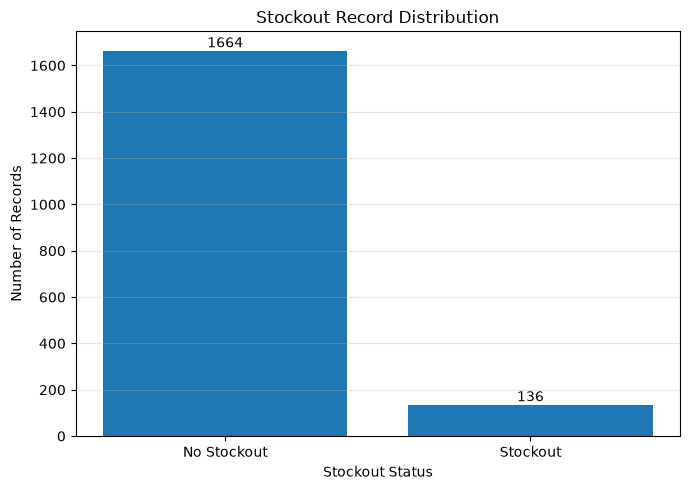

In [6]:
# Step 6: Stockout Analysis

import matplotlib.pyplot as plt

# Count stockout and non-stockout records
stockout_counts = (
    df["stockout_flag"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
)

no_stockout = int(stockout_counts.loc[0])
stockout = int(stockout_counts.loc[1])
total_records = no_stockout + stockout

print("STOCKOUT ANALYSIS")
print("-" * 40)
print("Records without stockout:", no_stockout)
print("Records with stockout:", stockout)
print("Total records:", total_records)

if total_records > 0:
    print(
        "Stockout percentage:",
        round(stockout / total_records * 100, 2),
        "%",
    )

# Plot the results
plt.figure(figsize=(7, 5))
bars = plt.bar(
    ["No Stockout", "Stockout"],
    [no_stockout, stockout],
)
plt.title("Stockout Record Distribution")
plt.xlabel("Stockout Status")
plt.ylabel("Number of Records")
plt.bar_label(bars)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

CORRELATION MATRIX
----------------------------------------


,opening_stock,units_received,units_sold,unit_price,discount_pct,days_to_expiry,temperature_c,waste_units,stockout_flag
opening_stock,1.00,0.01,0.66,-0.20,0.12,0.13,0.10,0.09,-0.34
units_received,0.01,1.00,0.00,0.03,0.01,0.03,0.01,0.10,-0.11
units_sold,0.66,0.00,1.00,-0.23,0.17,0.16,0.14,-0.04,-0.01
unit_price,-0.20,0.03,-0.23,1.00,-0.05,0.42,0.22,-0.01,0.01
discount_pct,0.12,0.01,0.17,-0.05,1.00,0.05,0.02,-0.02,0.03
days_to_expiry,0.13,0.03,0.16,0.42,0.05,1.00,0.14,0.02,-0.03
temperature_c,0.10,0.01,0.14,0.22,0.02,0.14,1.00,-0.00,0.02
waste_units,0.09,0.10,-0.04,-0.01,-0.02,0.02,-0.00,1.00,-0.07
stockout_flag,-0.34,-0.11,-0.01,0.01,0.03,-0.03,0.02,-0.07,1.00


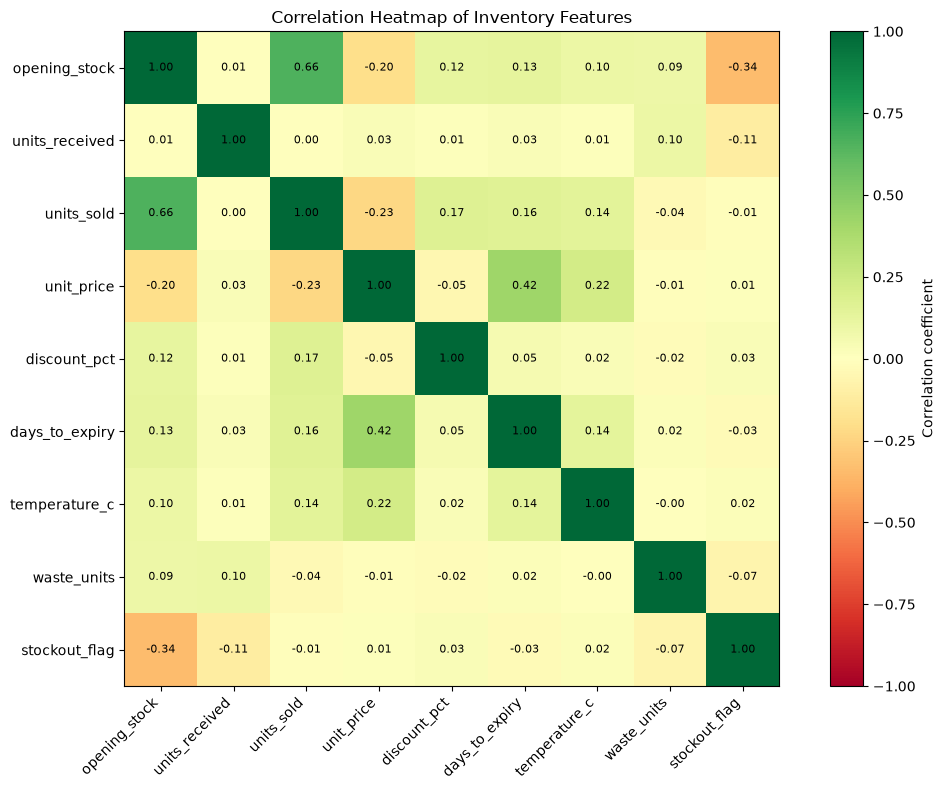

In [7]:
# Step 7: Correlation Analysis

import numpy as np
import matplotlib.pyplot as plt

# Product ID is an identifier, so we exclude it from correlation analysis.
numeric_cols = [
    "opening_stock",
    "units_received",
    "units_sold",
    "unit_price",
    "discount_pct",
    "days_to_expiry",
    "temperature_c",
    "waste_units",
    "stockout_flag",
]

corr = df[numeric_cols].corr()

print("CORRELATION MATRIX")
print("-" * 40)
display(corr.round(2))

# Plot the correlation heatmap
fig, ax = plt.subplots(figsize=(11, 8))

image = ax.imshow(corr, vmin=-1, vmax=1, cmap="RdYlGn")

ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))

ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)

for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        value = corr.iloc[i, j]
        ax.text(
            j,
            i,
            f"{value:.2f}",
            ha="center",
            va="center",
            fontsize=8,
        )

ax.set_title("Correlation Heatmap of Inventory Features")
fig.colorbar(image, ax=ax, label="Correlation coefficient")
plt.tight_layout()
plt.show()

In [8]:
# Step 8: Exploratory Data Analysis Summary

import pandas as pd

# Ensure the date column is in datetime format
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("=" * 55)
print("WASTEWISE AI - EDA SUMMARY AND FINDINGS")
print("=" * 55)

# 1. Dataset overview
print("\n1. DATASET OVERVIEW")
print("-" * 40)
print("Total records:", len(df))
print("Total columns:", len(df.columns))
print("Unique products:", df["product_id"].nunique())
print("Unique categories:", df["category"].nunique())
print("First recorded date:", df["date"].min())
print("Latest recorded date:", df["date"].max())

# 2. Sales and waste summary
print("\n2. SALES AND WASTE SUMMARY")
print("-" * 40)
print("Total units sold:", int(df["units_sold"].sum()))
print("Average units sold per record:", round(df["units_sold"].mean(), 2))
print("Total recorded waste units:", int(df["waste_units"].sum()))
print("Average waste units per record:", round(df["waste_units"].mean(), 2))

# 3. Category-wise performance
print("\n3. CATEGORY-WISE PERFORMANCE")
print("-" * 40)

category_summary = (
    df.groupby("category")
    .agg(
        total_sales=("units_sold", "sum"),
        total_waste=("waste_units", "sum"),
        records=("product_id", "size"),
    )
    .sort_values("total_sales", ascending=False)
)

display(category_summary)

if not category_summary.empty:
    print(
        "Highest sales category:",
        category_summary["total_sales"].idxmax(),
    )
    print(
        "Highest recorded waste category:",
        category_summary["total_waste"].idxmax(),
    )

# 4. Product-wise sales
print("\n4. PRODUCT-WISE SALES")
print("-" * 40)

product_summary = (
    df.groupby("product_id")
    .agg(
        total_sales=("units_sold", "sum"),
        total_waste=("waste_units", "sum"),
    )
    .sort_values("total_sales", ascending=False)
)

display(product_summary)

if not product_summary.empty:
    print("Highest-selling product ID:", product_summary.index[0])

# 5. Stockout summary
print("\n5. STOCKOUT SUMMARY")
print("-" * 40)

stockout_count = int((df["stockout_flag"] == 1).sum())
total_records = len(df)

print("Stockout records:", stockout_count)
print("Non-stockout records:", int((df["stockout_flag"] == 0).sum()))

if total_records > 0:
    print(
        "Stockout percentage:",
        round(stockout_count / total_records * 100, 2),
        "%",
    )

# 6. Missing and duplicate values
print("\n6. DATA QUALITY")
print("-" * 40)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

# 7. Correlation with sales and waste
print("\n7. NUMERICAL CORRELATION")
print("-" * 40)

numeric_df = df.select_dtypes(include="number")
correlation = numeric_df.corr()

if "units_sold" in correlation.columns:
    print("Features most correlated with units_sold:")
    display(
        correlation["units_sold"]
        .drop(labels=["units_sold"], errors="ignore")
        .sort_values(key=lambda s: s.abs(), ascending=False)
        .head(5)
        .to_frame("correlation_with_units_sold")
    )

if "waste_units" in correlation.columns:
    print("Features most correlated with waste_units:")
    display(
        correlation["waste_units"]
        .drop(labels=["waste_units"], errors="ignore")
        .sort_values(key=lambda s: s.abs(), ascending=False)
        .head(5)
        .to_frame("correlation_with_waste_units")
    )

print("\nEDA completed successfully.")
print("Use the tables and graphs above to document your findings.")

WASTEWISE AI - EDA SUMMARY AND FINDINGS

1. DATASET OVERVIEW
----------------------------------------
Total records: 1800
Total columns: 12
Unique products: 10
Unique categories: 4
First recorded date: 2026-04-01 00:00:00
Latest recorded date: 2026-09-27 00:00:00

2. SALES AND WASTE SUMMARY
----------------------------------------
Total units sold: 36267
Average units sold per record: 20.15
Total recorded waste units: 2602
Average waste units per record: 1.45

3. CATEGORY-WISE PERFORMANCE
----------------------------------------


,total_sales,total_waste,records
category,,,
Dairy,13239,1056,720
Produce,11428,810,540
Bakery,6585,459,360
Beverage,5015,277,180


Highest sales category: Dairy
Highest recorded waste category: Dairy

4. PRODUCT-WISE SALES
----------------------------------------


,total_sales,total_waste
product_id,,
1006,6001,189
1002,5408,311
1008,5015,277
1003,4672,195
1004,3535,275
1005,3525,383
1009,2428,157
1010,1913,264
1007,1902,238


Highest-selling product ID: 1006

5. STOCKOUT SUMMARY
----------------------------------------
Stockout records: 136
Non-stockout records: 1664
Stockout percentage: 7.56 %

6. DATA QUALITY
----------------------------------------
Total missing cells: 0
Duplicate rows: 0

7. NUMERICAL CORRELATION
----------------------------------------
Features most correlated with units_sold:


,correlation_with_units_sold
opening_stock,0.661844
unit_price,-0.231365
product_id,-0.206964
discount_pct,0.168149
days_to_expiry,0.156804


Features most correlated with waste_units:


,correlation_with_waste_units
units_received,0.099191
opening_stock,0.089464
stockout_flag,-0.069077
units_sold,-0.036931
product_id,-0.022857



EDA completed successfully.
Use the tables and graphs above to document your findings.
